# Laboratorium 2 - wieloręcy bandyci

## Przygotowanie

 * [opcjonalnie] Utwórz wirtualne środowisko
 `python3 -m venv ./recsyslab2`
 * zainstaluj potrzebne biblioteki:
 `pip3 install matplotlib`
 * upewnij się, że plik `bandit_framework.py` znajduje się w tym samym katalogu

## Część 1. - framework i naiwni bandyci

### Framework

Plik `bandit_framework.py` zawiera:
 * `Arm` - ramię o zadanym prawdopodobieństwie kliknięcia `click_probability`. Metoda `pull()` zwraca 1 (kliknięcie) lub 0. Bandyci **nie znają** tego prawdopodobieństwa - muszą się go nauczyć.
 * `Bandit` - klasa bazowa wszystkich algorytmów. Kontrakt:
   * `recommend(size)` zwraca listę **dokładnie** `size` **różnych** identyfikatorów ramion,
   * `feedback(arm_id, reward)` jest wywoływana po każdej rekomendacji **osobno dla każdego zarekomendowanego ramienia**, z nagrodą 0 lub 1.
 * `Runner` - przeprowadza symulację. W każdej epoce prosi bandytę o rekomendację, sprawdza jej poprawność (rozmiar, duplikaty, nieznane ramiona), pociąga każde zarekomendowane ramię i przekazuje bandycie wynik przez `feedback()`. Metoda `simulate()` zwraca listę obiektów `SimulationResult` (po jednym na bandytę) z nagrodą (reward) i regretem w każdej epoce.

Bandyci uczą się w trakcie symulacji, więc przed każdą nową symulacją trzeba ich utworzyć od nowa.

### Metryka - regret

Liczba kliknięć jest losowa i nie mówi wprost, jak daleko jesteśmy od ideału. Dlatego głównie patrzymy na **regret** - różnicę między oczekiwaną nagrodą najlepszej możliwej rekomendacji a oczekiwaną nagrodą rekomendacji bandyty:

$$\text{regret}_t = \sum_{a \in A^*} p_a - \sum_{a \in A_t} p_a$$

gdzie $A^*$ to zbiór ramion o najwyższym CTR, $A_t$ - rekomendacja bandyty w epoce $t$, a $p_a$ - prawdziwe prawdopodobieństwo kliknięcia ramienia $a$. Regret liczymy z prawdziwych prawdopodobieństw, więc nie zależy od szczęścia w losowaniu kliknięć.

Na wykresach pokazujemy **skumulowany regret** $\sum_{t} \text{regret}_t$:
 * jeśli rośnie liniowo - bandyta się nie uczy (albo wciąż płaci za eksplorację),
 * jeśli się wypłaszcza - bandyta znalazł najlepsze ramiona.

In [1]:
# importujemy wszystkie potrzebne pakiety

from copy import copy
from dataclasses import dataclass
from math import inf, log, sqrt
from random import betavariate, choice, random, sample, seed, shuffle, uniform
from typing import Dict, List, NamedTuple, Tuple
from bandit_framework import *  # pakiet ze srodowiskiem testowym

In [2]:
# inicjalizujemy parametry testu

seed(42)  # dla powtarzalnosci wynikow
epochs = 200
recommendation_size = 10

In [3]:
# inicjalizujemy ramiona bandytow
# ramiona dzielimy na grupy; CTR ramienia losujemy z przedzialu przypisanego do jego grupy
# nazwy ramion (np. top_3) sluza tylko nam do analizy wynikow - bandyci nie powinni z nich korzystac

class ArmTier(NamedTuple):
    name: str
    count: int
    ctr_range: Tuple[float, float]


def create_arms(tiers: List[ArmTier]) -> Dict[str, Arm]:
    all_arms = [Arm(f'{tier.name}_{i}', uniform(*tier.ctr_range)) for tier in tiers for i in range(tier.count)]
    shuffle(all_arms)
    return {arm.arm_id: arm for arm in all_arms}


tiers = [
    ArmTier('top', 5, (0.5, 0.7)),
    ArmTier('good', 15, (0.3, 0.5)),
    ArmTier('average', 50, (0.1, 0.3)),
    ArmTier('poor', 130, (0.0, 0.1)),
]
arms = create_arms(tiers)
arm_ids = list(arms.keys())

In [4]:
best_expected_reward = sum(sorted([arm.click_probability for arm in arms.values()], reverse=True)[:recommendation_size])
print(f'Number of arms: {len(arms)}')
print(f'Expected highest reward per epoch: {best_expected_reward:.2f}')

Number of arms: 200
Expected highest reward per epoch: 5.10


In [5]:
# pierwszy bandyta - wybiera losowe ramiona

class Random(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str]):
        super().__init__(bandit_id, arm_ids)

    def recommend(self, size: int) -> List[str]:
        return sample(self.arm_ids, size)

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [6]:
# drugi bandyta (wyrocznia) korzysta z wiedzy, do ktorej przecietny bandyta nie ma dostepu

class Oracle(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], arms: Dict[str, Arm]):
        super().__init__(bandit_id, arm_ids)
        self.ranking = sorted(arm_ids, key=lambda arm_id: arms[arm_id].click_probability, reverse=True)

    def recommend(self, size: int) -> List[str]:
        return self.ranking[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [7]:
# tworzymy liste bandytow do przetestowania

bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms)
]

In [8]:
# uruchamiamy test

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle

bandit                 total reward   total regret
oracle                         1022            0.0
random                          250          775.9


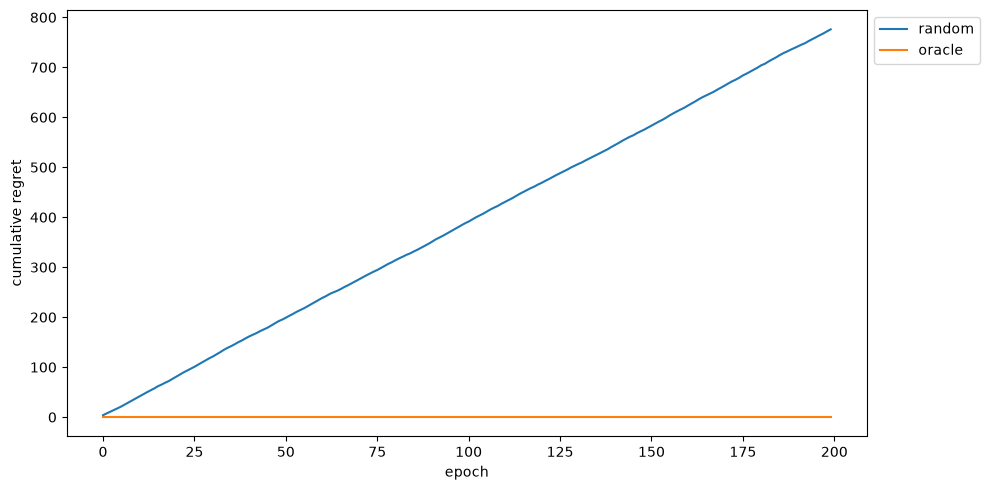

In [9]:
# skumulowany regret

runner.plot_results(results, mode='regret')

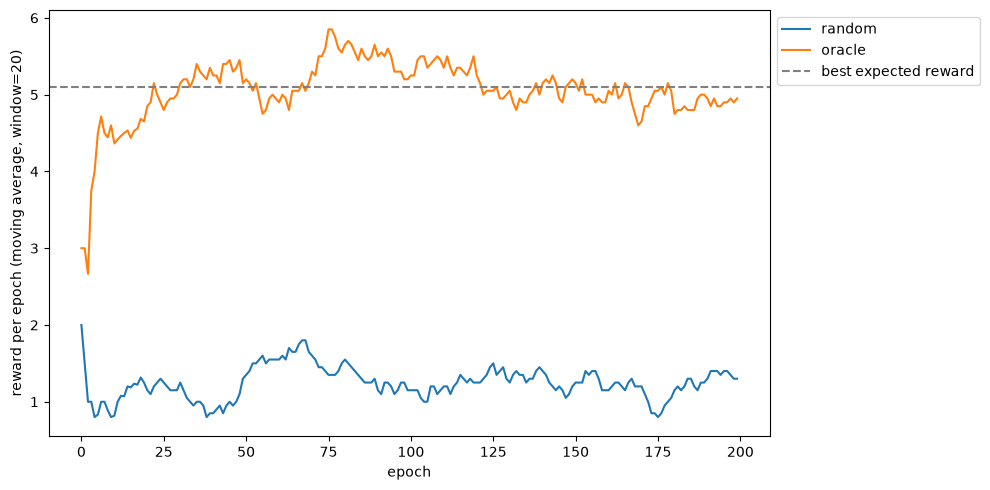

In [10]:
# reward (liczba klikniec) per epoka

runner.plot_results(results, mode='reward')

## Część 2. - ε-greedy

In [11]:
# statystyki, ktore bandyta zbiera o jednym ramieniu - uzyjemy ich we wszystkich bandytach

@dataclass
class ArmStats:
    trials: int = 0     # ile razy ramie bylo rekomendowane
    successes: int = 0  # ile razy zostalo klikniete

    @property
    def failures(self) -> int:
        return self.trials - self.successes

    @property
    def mean(self) -> float:  # srednia nagroda - empiryczny CTR
        return self.successes / self.trials if self.trials > 0 else 0.0

    def update(self, reward: int) -> None:
        self.trials += 1
        self.successes += reward

In [12]:
class EGreedy(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], epsilon: float):
        super().__init__(bandit_id, arm_ids)
        self.epsilon = epsilon
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        srtd = sorted(self.arm_ids, key = lambda x: self.stats[x].mean, reverse=True)
        rndm = sample(self.arm_ids, len(self.arm_ids))
        recs = [None for _ in range(size)]
        i, j = 0, 0
        while not recs[-1]:
            rec = srtd[i] if random() > self.epsilon else rndm[i]
            if rec not in recs:
                recs[j] = rec
                j += 1
            i += 1
        return recs

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [13]:
# porownujemy kilka wartosci epsilon

bandits = [EGreedy(f'egreedy_{epsilon}', arm_ids, epsilon) for epsilon in [0, 0.05, 0.25, 0.5]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: egreedy_0
Simulating: egreedy_0.05
Simulating: egreedy_0.25
Simulating: egreedy_0.5

bandit                 total reward   total regret
egreedy_0.25                    653          382.3
egreedy_0.5                     550          496.3
egreedy_0.05                    382          638.4
egreedy_0                       239          775.0


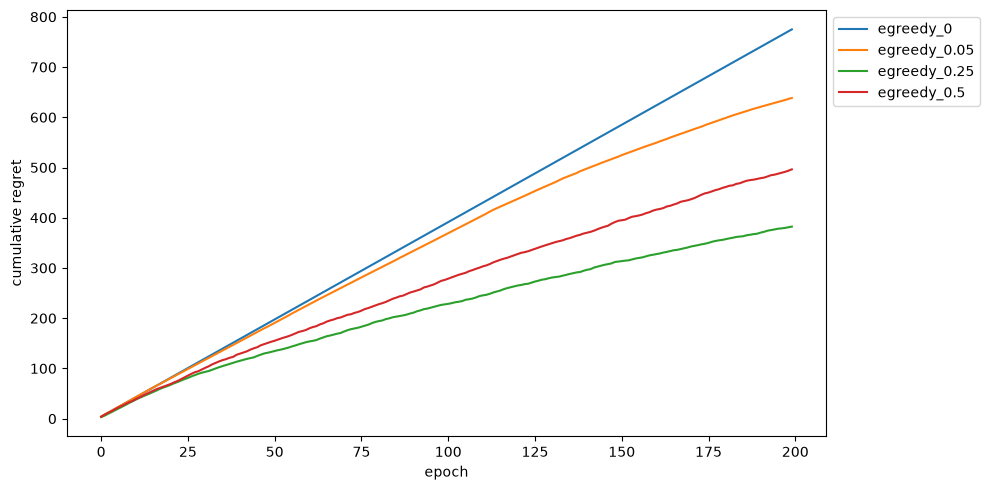

In [14]:
runner.plot_results(results, mode='regret')

In [15]:
# mozemy sprawdzic, jaka wiedze bandyta zdobyl o poszczegolnych ramionach

trained = next(bandit for bandit in bandits if bandit.bandit_id == 'egreedy_0.25')
top_arms = sorted(arm_ids, key=lambda arm_id: trained.stats[arm_id].mean, reverse=True)[:recommendation_size]

print(f"{'arm':<12}{'trials':>8}{'successes':>11}{'mean':>7}{'true CTR':>10}")
for arm_id in top_arms:
    stats = trained.stats[arm_id]
    print(f'{arm_id:<12}{stats.trials:>8}{stats.successes:>11}{stats.mean:>7.2f}{arms[arm_id].click_probability:>10.2f}')

arm           trials  successes   mean  true CTR
average_27         2          2   1.00      0.16
top_4            149         99   0.66      0.65
good_1            91         57   0.63      0.48
good_9            41         25   0.61      0.43
top_2            136         82   0.60      0.56
top_3            136         70   0.51      0.54
good_0            68         30   0.44      0.44
good_10          158         66   0.42      0.41
good_6           103         42   0.41      0.40
average_18        33         11   0.33      0.27


## Część 3. - UCB (Upper Confidence Bound)

In [16]:
class UCB(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], optimism_weight: float):
        super().__init__(bandit_id, arm_ids)
        self.optimism_weight = optimism_weight
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        total_trials = sum(self.stats[arm_id].trials for arm_id in self.arm_ids)
        return sorted(self.arm_ids, key = lambda x: self.sort_val(x, total_trials), reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

    def sort_val(self, arm_id, total_trials):
        if self.stats[arm_id].trials == 0:
            opt = inf
        else:
            opt = sqrt(2 * log(total_trials) / self.stats[arm_id].trials)
        return self.stats[arm_id].mean + self.optimism_weight * opt

In [17]:
bandits = [UCB(f'ucb_{optimism_weight}', arm_ids, optimism_weight) for optimism_weight in [0.01, 0.1, 0.3, 1]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ucb_0.01
Simulating: ucb_0.1
Simulating: ucb_0.3
Simulating: ucb_1

bandit                 total reward   total regret
ucb_0.1                         712          310.0
ucb_0.3                         592          424.6
ucb_0.01                        569          458.8
ucb_1                           305          702.9


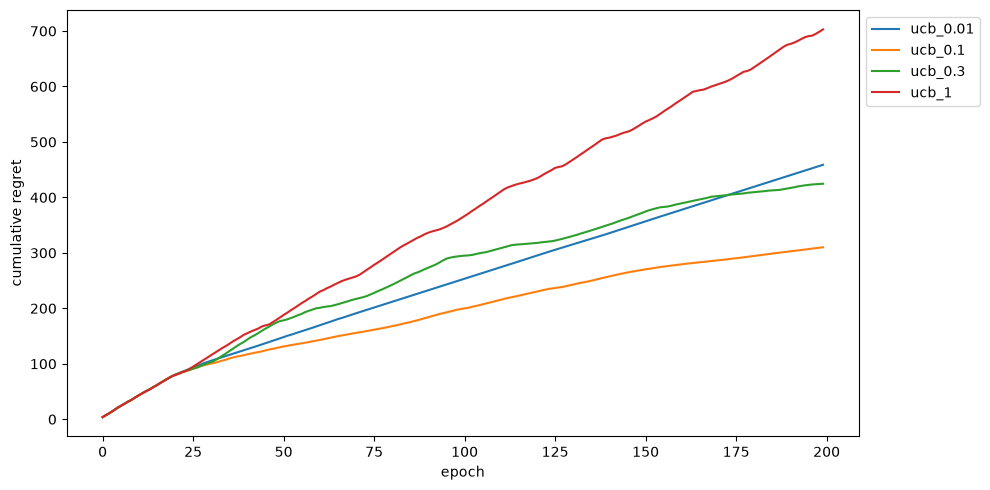

In [18]:
runner.plot_results(results, mode='regret')

## Część 4. - Thompson Sampling

In [19]:
class ThompsonSampling(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], reward_multiplier: float, regret_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.reward_multiplier = reward_multiplier
        self.regret_multiplier = regret_multiplier
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        betas = {arm_id: betavariate(1 + stats.successes * self.reward_multiplier,
                                     1 + stats.failures * self.regret_multiplier)
                 for arm_id, stats in self.stats.items()}
        return sorted(self.arm_ids, key=lambda x: betas[x], reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [20]:
bandits = [ThompsonSampling(f'ts_{reward_multiplier}_{regret_multiplier}', arm_ids, reward_multiplier, regret_multiplier)
           for reward_multiplier, regret_multiplier in [(1, 1), (10, 10), (1, 10), (10, 1)]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ts_1_1
Simulating: ts_10_10
Simulating: ts_1_10
Simulating: ts_10_1

bandit                 total reward   total regret
ts_10_10                        779          233.1
ts_10_1                         685          345.3
ts_1_10                         596          462.1
ts_1_1                          499          533.4


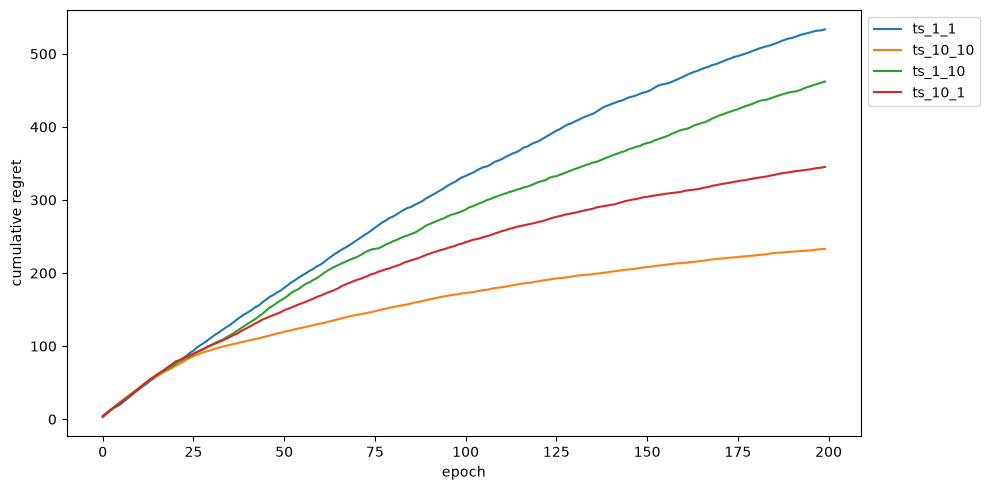

In [21]:
runner.plot_results(results, mode='regret')

## Część 5. - Własny bandyta

Zaimplementuj własny algorytm bandyty. Może to być np. bandyta Softmax, Thompson Sampling z dwoma rozkładami beta, Thompson Sampling z rozkładem innnym niż beta lub cokolwiek innego, co ci przyjdzie do głowy.

In [22]:
# recommend the arms with the biggest failure streaks - you're due after all ;)
class GamblersFallacyBandit(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str]):
        super().__init__(bandit_id, arm_ids)
        self.fail_streak = {arm_id: 0 for arm_id in arm_ids}
        # recommended streak to not choose the same arms the entire time
        # tiebreaker, smaller recommended streak - prefer it
        self.rec_streak = {arm_id: 0 for arm_id in arm_ids}

    def sort_val(self, arm_id):
        return 1e6 * self.fail_streak[arm_id] - self.rec_streak[arm_id]

    def recommend(self, size: int) -> List[str]:
        recs = sorted(self.arm_ids, key=lambda x: self.sort_val(x), reverse=True)[:size]
        for arm_id in self.rec_streak:
            if arm_id in recs:
                self.rec_streak[arm_id] += 1
            else:
                self.rec_streak[arm_id] = 0
        return recs

    def feedback(self, arm_id: str, reward: int) -> None:
        if reward == 0:
            self.fail_streak[arm_id] += 1
        else:
            self.fail_streak[arm_id] = 0

In [23]:
bandits = [GamblersFallacyBandit("gamblers_fallacy", arm_ids)]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: gamblers_fallacy

bandit                 total reward   total regret
gamblers_fallacy                248          781.5


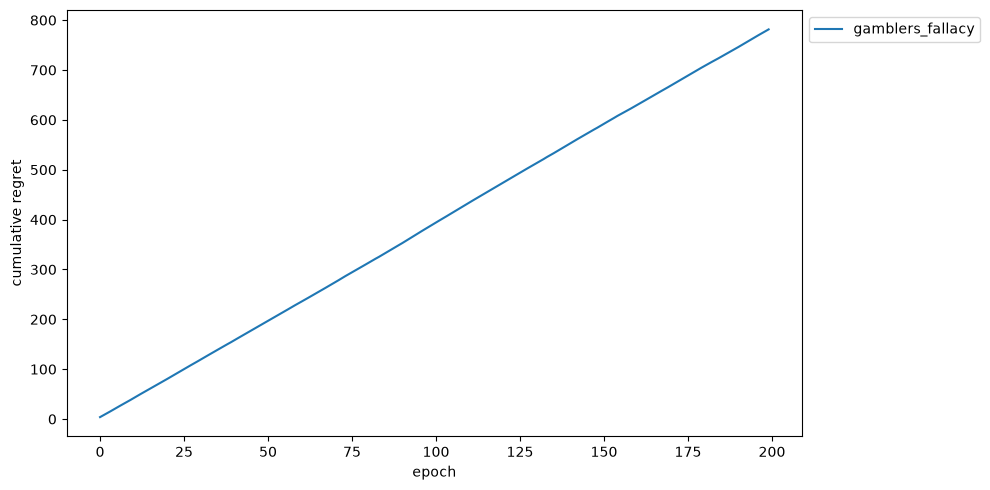

In [24]:
runner.plot_results(results, mode='regret')

## Część 6. - porównanie bandytów

In [25]:
# tworzymy nowych bandytow na potrzeby porowwnania
# mozesz wykorzystac parametry znalezione na wczesniejszych etapach lub przetestowac nowe
bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms),
    EGreedy('egreedy', arm_ids, epsilon=0.25),
    UCB('ucb', arm_ids, optimism_weight=0.1),
    ThompsonSampling('ts', arm_ids, reward_multiplier=10, regret_multiplier=1),
    GamblersFallacyBandit("gamblers_fallacy", arm_ids)
]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: gamblers_fallacy

bandit                 total reward   total regret
oracle                         1039            0.0
ucb                             752          252.7
ts                              769          257.5
egreedy                         680          368.6
random                          234          766.4
gamblers_fallacy                221          785.7


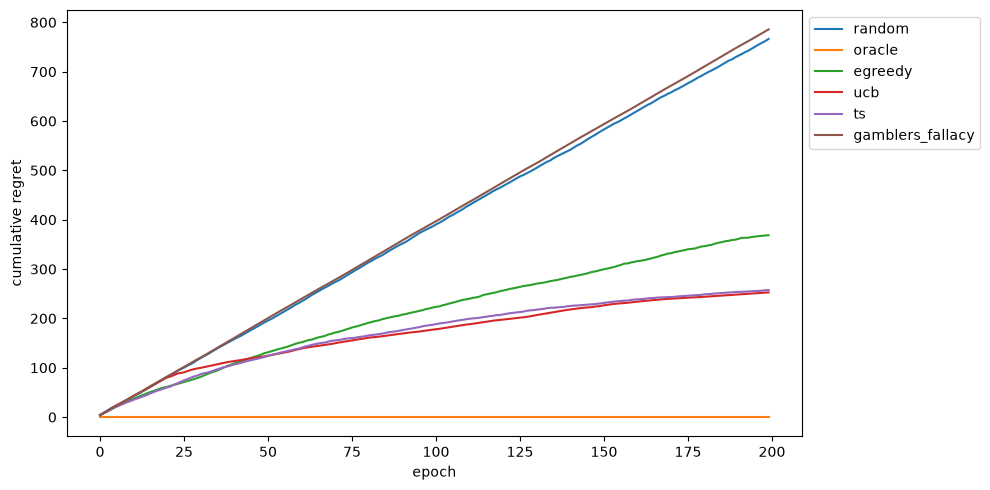

In [26]:
runner.plot_results(results, mode='regret')

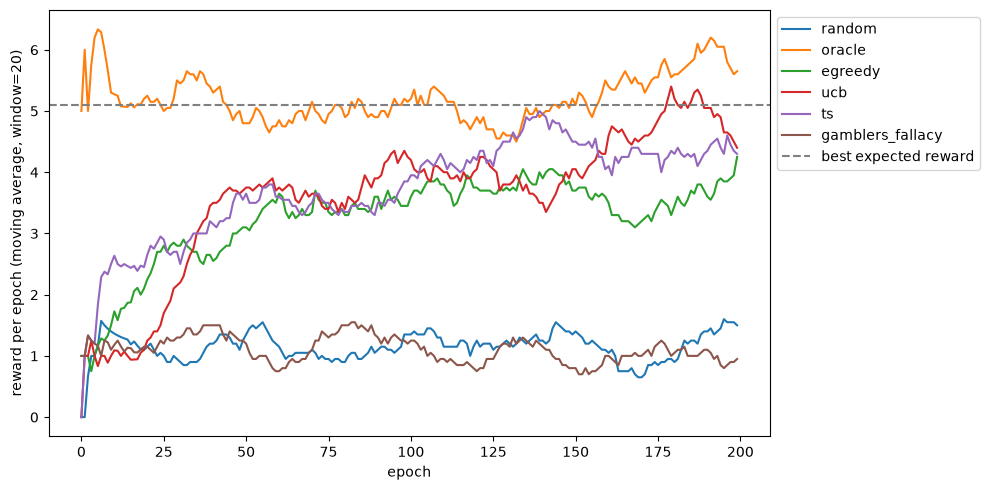

In [27]:
runner.plot_results(results, mode='reward')